# Buổi E6: Mô hình dựa vào cột nào? Độ quan trọng đúng cách

**Hiện trường.** Chị Hạnh có một rừng ngẫu nhiên dự đoán tiến triển bệnh tiểu đường. Hội đồng hỏi: *"mô hình dựa vào chỉ số nào nhiều nhất? có thể bỏ bớt xét nghiệm nào không?"* Ở E2 cô đã thấy `feature_importances_` của cây có thể **thổi phồng** cột nhiễu. Cô cần một cách đo đáng tin hơn.

Buổi này dạy **độ quan trọng hoán vị** (*permutation importance*): **xáo một cột** trong tập thi và xem **điểm thi tụt bao nhiêu**. Cột nào xáo mà điểm tụt mạnh thì mô hình **thật sự cần** nó.

**Ẩn dụ:** muốn biết một cầu thủ có quan trọng không, **cho anh ta nghỉ một trận** và xem đội thua bao nhiêu bàn. Không nghe lời kể "anh ấy chạy nhiều" (đó là độ quan trọng kiểu cây: đo mức dùng, không đo mức cần).

**Mindset của người làm dữ liệu:** độ quan trọng là **công cụ gỡ lỗi mô hình** (phát hiện rò rỉ, cột vô dụng), không phải bằng chứng về **nguyên nhân** ngoài đời.

**Lưu ý:** dữ liệu mẫu để học, không dùng ra quyết định y tế thật.

## Bản đồ các chặng

| Chặng | Câu hỏi của chặng |
|---|---|
| Chặng 0 | Thấy ngay: hai bảng xếp hạng cột, hai câu chuyện khác nhau? |
| Chặng 1 | Tự làm hoán vị bằng tay |
| Chặng 2 | Đo trên tập học hay tập thi? Cột nhiễu lộ mặt |
| Chặng 3 | Cột tương quan: hai cầu thủ thay nhau |
| Chặng 4 | Hướng của ảnh hưởng: đồ thị phụ thuộc từng phần |
| Chặng 5 | Dùng để gỡ lỗi, không để kết luận nhân quả |

## Chặng 0: Thấy ngay, hai bảng xếp hạng

**Câu hỏi:** mô hình dựa vào cột nào nhiều nhất?

Dữ liệu `diabetes` (442 bệnh nhân, 10 cột). Ta **thêm một cột nhiễu hoàn toàn ngẫu nhiên** (dựng có chủ đích, tên `random_noise`) để kiểm tra phép đo có bị đánh lừa không.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
BLUE, GRAY = "#1F4E79", "#8C8C8C"
plt.rcParams["figure.figsize"] = (6, 4)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

**Giải thích từng dòng**

- `import numpy as np`: mượn thư viện numpy (máy tính bỏ túi cho cả dãy số), đặt tên ngắn là `np` để gõ cho nhanh.
- `import pandas as pd`: mượn pandas, thư viện làm việc với bảng số liệu giống Excel, tên ngắn là `pd`.
- `import matplotlib.pyplot as plt`: mượn công cụ vẽ biểu đồ, tên ngắn là `plt`.
- `BLUE, GRAY = "#1F4E79", "#8C8C8C"`: gán hai màu dùng suốt bài (xanh đậm và xám). Một dòng gán cùng lúc hai biến, mỗi biến một mã màu.
- `plt.rcParams["figure.figsize"] = (6, 4)`: đặt cỡ hình mặc định: rộng 6, cao 4 (đơn vị inch).
- `plt.rcParams["axes.spines.top"] = False`: bỏ đường viền phía trên khung hình cho gọn mắt.
- `plt.rcParams["axes.spines.right"] = False`: bỏ luôn đường viền bên phải.

In [2]:
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
X, y = load_diabetes(return_X_y=True, as_frame=True)
rng = np.random.RandomState(0)
X["random_noise"] = rng.randn(len(X))
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)
rf = RandomForestRegressor(n_estimators=300, min_samples_leaf=3, random_state=0, n_jobs=-1).fit(X_train, y_train)
print("train R2:", round(rf.score(X_train, y_train), 3), "| test R2:", round(rf.score(X_test, y_test), 3))
impurity = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)
print(impurity.round(3).to_string())

train R2: 0.855 | test R2: 0.321
bmi             0.318
s5              0.315
bp              0.088
s3              0.057
s6              0.043
random_noise    0.042
s2              0.037
age             0.036
s1              0.032
s4              0.022
sex             0.007


**Giải thích từng dòng**

- `X["random_noise"] = rng.randn(len(X))`: thêm một cột số ngẫu nhiên, **không liên quan** gì đến `y`.
- `RandomForestRegressor(n_estimators=300, min_samples_leaf=3, ...)`: rừng hồi quy (E2, trung bình thay vì bỏ phiếu). `min_samples_leaf=3` là phanh nhẹ.
- `pd.Series(rf.feature_importances_, index=X.columns)`: ghép độ quan trọng kiểu cây (E2) với tên cột để đọc cho dễ.
- `.sort_values(ascending=False)`: xếp từ cao xuống thấp.

**Cách đọc.**
- **Con số:** R² học **0,85**, R² thi **0,32**. Độ quan trọng kiểu cây gán cho `random_noise` **0,042** (xếp hạng 6/11).
- **Bức tranh:** bảng xếp hạng này đo **mức cây dùng cột khi chia nhánh trên tập học**. Cột nhiễu vẫn có một phần, vì cây có thể chia theo nhiễu để vá phần học.
- **Câu hỏi tiếp:** cách đo nào hỏi đúng câu *"bỏ cột này thì điểm **thi** tụt bao nhiêu"*?

**Mang về chặng 0:** độ quan trọng kiểu cây đo mức dùng khi học, không đo mức cần khi thi.

## Chặng 1: Tự làm hoán vị bằng tay

**Câu hỏi:** làm sao đo "mô hình cần cột này đến đâu"?

Các bước:
1. Chấm điểm mô hình trên tập thi bình thường (điểm gốc).
2. **Xáo ngẫu nhiên** thứ tự giá trị của **một** cột trong tập thi: cột đó còn nguyên phân phối nhưng **mất liên hệ** với `y`.
3. Chấm lại. **Điểm tụt** bao nhiêu thì cột đó quan trọng bấy nhiêu.
4. Lặp vài lần (xáo khác nhau) và trung bình, rồi chuyển sang cột kế.

Mô hình **không học lại**: chỉ đổi dữ liệu đưa vào.

In [3]:
base = rf.score(X_test, y_test)
rows = []
for col in X.columns:
    drops = []
    for rep in range(10):
        Xs = X_test.copy()
        Xs[col] = rng.permutation(Xs[col].values)
        drops.append(base - rf.score(Xs, y_test))
    rows.append({"column": col, "R2 drop (mean)": np.mean(drops), "std": np.std(drops)})
by_hand = pd.DataFrame(rows).sort_values("R2 drop (mean)", ascending=False).reset_index(drop=True)
print("baseline test R2:", round(base, 3))
print(by_hand.round(3).to_string(index=False))

baseline test R2: 0.321
      column  R2 drop (mean)   std
          s5           0.206 0.048
         bmi           0.176 0.037
          bp           0.033 0.032
          s6           0.006 0.008
         sex           0.005 0.003
          s2           0.003 0.009
random_noise           0.000 0.009
          s4          -0.001 0.010
          s1          -0.003 0.006
          s3          -0.005 0.011
         age          -0.006 0.004


**Giải thích từng dòng**

- `X_test.copy()`: sao chép tập thi trước khi xáo, để tập thi gốc không bị hỏng.
- `rng.permutation(Xs[col].values)`: xáo ngẫu nhiên thứ tự các giá trị của cột (hoán vị).
- `base - rf.score(Xs, y_test)`: **điểm tụt**: điểm gốc trừ điểm sau khi xáo. Số dương lớn là cột quan trọng.
- `for rep in range(10):`: xáo 10 lần để lấy trung bình và độ lệch, vì mỗi lần xáo cho kết quả hơi khác.

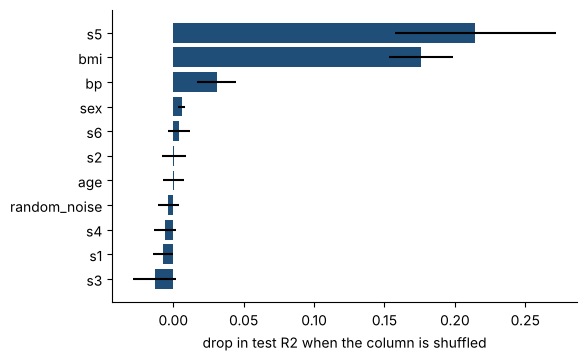

In [4]:
from sklearn.inspection import permutation_importance
pi = permutation_importance(rf, X_test, y_test, n_repeats=10, random_state=0, n_jobs=-1)
lib = pd.DataFrame({"mean": pi.importances_mean, "std": pi.importances_std}, index=X.columns).sort_values("mean", ascending=False)
fig, ax = plt.subplots(figsize=(6, 3.8))
ax.barh(lib.index[::-1], lib["mean"][::-1], xerr=lib["std"][::-1], color=BLUE)
ax.set_xlabel("drop in test R2 when the column is shuffled")
plt.show()

**Giải thích từng dòng**

- `permutation_importance(rf, X_test, y_test, n_repeats=10)`: hàm có sẵn làm đúng việc trên: xáo từng cột `n_repeats` lần và đo điểm tụt.
- `pi.importances_mean / pi.importances_std`: trung bình và độ lệch của điểm tụt, mỗi cột một số.
- `ax.barh(...)`: biểu đồ cột nằm ngang; `[::-1]` đảo thứ tự để cột quan trọng nhất nằm trên cùng.

**Cách đọc.**
- **Con số:** cột quan trọng nhất theo hoán vị là **s5** (R² tụt **0,214**); thứ hai **bmi** (**0,176**). Cột nhiễu `random_noise`: tụt **-0,003** (± 0,008).
- **Bức tranh:** cột nhiễu quanh **0** (có thể hơi âm: xáo ngẫu nhiên đôi khi vô tình tốt hơn). Cột thật quan trọng có điểm tụt rõ rệt, lớn hơn nhiều độ lệch. Bản tự viết và bản của thư viện cho **cùng một câu chuyện** (khác chút ở số lần xáo).
- **Quy tắc đọc:** điểm tụt phải **lớn hơn độ lệch** mới đáng tin; điểm tụt nhỏ hơn độ lệch xem như bằng 0.
- **Câu hỏi tiếp:** nếu đo trên tập **học** thay vì tập thi thì sao?

**Mang về chặng 1:** độ quan trọng hoán vị = điểm tụt khi xáo một cột; cột nhiễu quanh 0.

## Chặng 2: Đo trên tập học hay tập thi?

**Câu hỏi:** xáo trên tập học có cho kết quả giống tập thi không?

Rừng đã **học thuộc một phần** nhiễu trong tập học, nên nếu xáo cột nhiễu **trên tập học** thì điểm cũng tụt (mô hình đã dùng nó để "nhớ" các dòng). Trên tập **thi**, nhiễu không giúp ích nên tụt xấp xỉ 0.

In [5]:
pi_train = permutation_importance(rf, X_train, y_train, n_repeats=10, random_state=0, n_jobs=-1)
cmp = pd.DataFrame({"on train": pi_train.importances_mean, "on test": pi.importances_mean}, index=X.columns).sort_values("on test", ascending=False)
print(cmp.round(3).to_string())

              on train  on test
s5               0.428    0.214
bmi              0.370    0.176
bp               0.106    0.031
sex              0.010    0.006
s6               0.046    0.004
s2               0.038    0.001
age              0.038    0.000
random_noise     0.039   -0.003
s4               0.023   -0.006
s1               0.033   -0.007
s3               0.083   -0.013


**Giải thích từng dòng**

- `permutation_importance(rf, X_train, y_train, ...)`: cùng hàm nhưng chấm trên **tập học**.

**Cách đọc.**
- **Con số:** cột nhiễu: tụt **0,039** khi đo trên tập học, **-0,003** khi đo trên tập thi.
- **Bức tranh:** đo trên tập học có thể cho cột nhiễu một giá trị dương nhờ mô hình đã nhớ nó; đo trên tập thi thì không. Mỗi cột nào **chỉ có giá trị ở tập học** là dấu hiệu **học vẹt** (D2).
- **Quy tắc:** luôn đo trên **dữ liệu mô hình chưa thấy** (tập thi hoặc phần xác nhận), không phải tập học.

**Mang về chặng 2:** đo hoán vị trên tập thi (hoặc xác nhận), vì tập học sẽ khen cả cái mô hình đã học thuộc.

## Chặng 3: Cột tương quan, hai cầu thủ thay nhau

**Câu hỏi:** nếu hai cột mang gần như **cùng thông tin**, độ quan trọng hoán vị nói gì?

Đời thường: hai tiền đạo dự bị cho nhau. Cho một người nghỉ, người kia vào thay, đội gần như không thua thêm. Ta kết luận sai rằng "cả hai đều không quan trọng". Thí nghiệm: **sao chép cột `bmi`** (thêm `bmi_copy` giống hệt, cộng chút nhiễu rất nhỏ), huấn luyện lại rồi đo.

In [6]:
X2 = X.copy()
X2["bmi_copy"] = X2["bmi"] + rng.randn(len(X2)) * 0.002
a, b, ya, yb = train_test_split(X2, y, test_size=0.3, random_state=0)
rf2 = RandomForestRegressor(n_estimators=300, min_samples_leaf=3, random_state=0, n_jobs=-1).fit(a, ya)
pi2 = permutation_importance(rf2, b, yb, n_repeats=10, random_state=0, n_jobs=-1)
twin = pd.Series(pi2.importances_mean, index=X2.columns)
print("one at a time -> bmi:", round(twin["bmi"], 3), "| bmi_copy:", round(twin["bmi_copy"], 3), "| (bmi alone before the copy was added:", round(lib.loc["bmi", "mean"], 3), ")")
both = b.copy()
perm = rng.permutation(len(both))
both[["bmi", "bmi_copy"]] = both[["bmi", "bmi_copy"]].values[perm]
print("shuffle BOTH together -> R2 drop:", round(rf2.score(b, yb) - rf2.score(both, yb), 3))

one at a time -> bmi: 0.004 | bmi_copy: 0.061 | (bmi alone before the copy was added: 0.176 )
shuffle BOTH together -> R2 drop: 0.183


**Giải thích từng dòng**

- `X2["bmi_copy"] = X2["bmi"] + rng.randn(len(X2)) * 0.002`: cột bản sao gần y hệt `bmi` (nhiễu rất nhỏ so với độ phân tán của cột).
- `both[["bmi", "bmi_copy"]].values[perm]`: xáo **cùng một thứ tự** cho cả hai cột (cặp giá trị đi cùng nhau), tức coi hai cột là **một nhóm**.
- `rf2.score(b, yb) - rf2.score(both, yb)`: điểm tụt khi xáo cả nhóm.

**Cách đọc.**
- **Con số:** khi xáo **từng cột**, `bmi` tụt **0,004** và `bmi_copy` tụt **0,061**; trước khi có bản sao, `bmi` tụt **0,176**. Xáo **cả nhóm** hai cột: tụt **0,183**.
- **Bức tranh:** thông tin nằm ở hai nơi; xáo một cột thì cột kia vẫn cho mô hình dùng, nên mỗi cột riêng lẻ **trông ít quan trọng hơn** thực tế. Xáo cả nhóm mới thấy giá trị gộp.
- **Cách phòng:** khi nghi hai cột trùng thông tin (tương quan cao), **gom thành nhóm và xáo cùng nhau**, hoặc bỏ bớt một cột rồi đo lại. Đừng kết luận "bỏ cả hai cũng được" chỉ từ độ quan trọng từng cột.

**Mang về chặng 3:** cột tương quan chia nhau độ quan trọng; đo theo nhóm để thấy giá trị thật.

## Chặng 4: Hướng của ảnh hưởng, đồ thị phụ thuộc từng phần

**Câu hỏi:** cột quan trọng thì **tăng cột đó lên** dự đoán đổi thế nào?

Độ quan trọng chỉ cho biết **mức cần**, không cho biết **chiều**. **Đồ thị phụ thuộc từng phần** (*partial dependence*) trả lời: cố định mọi cột khác như dữ liệu thật, **quét một cột từ thấp đến cao** và vẽ dự đoán trung bình.

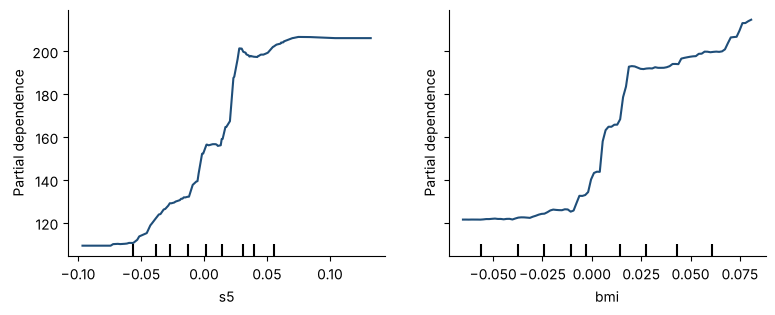

columns plotted: ['s5', 'bmi']


In [7]:
from sklearn.inspection import PartialDependenceDisplay
top2 = list(lib.index[:2])
fig, ax = plt.subplots(1, 2, figsize=(9, 3.2), sharey=True)
PartialDependenceDisplay.from_estimator(rf, X_test, top2, ax=ax, line_kw={"color": BLUE})
plt.show()
print("columns plotted:", top2)

**Giải thích từng dòng**

- `PartialDependenceDisplay.from_estimator(rf, X_test, top2, ax=ax)`: vẽ với mỗi cột trong `top2`: dự đoán trung bình khi cột đó chạy từ thấp đến cao.
- `line_kw={"color": BLUE}`: chỉnh màu đường vẽ.

**Cách đọc.**
- **Con số:** hai cột vẽ là **s5** và **bmi** (hai cột quan trọng nhất theo hoán vị).
- **Bức tranh:** đường **dốc lên** nghĩa là cột tăng thì dự đoán tiến triển bệnh tăng, nhìn từ **mô hình** (không phải từ cơ thể). Đường **phẳng** là cột ít ảnh hưởng ở vùng đó. Các cột trong bộ này đã chuẩn hóa nên giá trị trục x không có đơn vị y học.
- **Cảnh báo:** nếu cột tương quan mạnh với cột khác, việc "quét một cột, giữ các cột khác" tạo ra các **bệnh nhân không có thật**; đọc đồ thị với sự dè dặt.

**Mang về chặng 4:** hoán vị cho biết mức cần; đồ thị phụ thuộc từng phần cho biết chiều (theo mô hình).

## Chặng 5: Dùng để gỡ lỗi, không để kết luận nhân quả

**Dùng độ quan trọng để làm gì:**

1. **Gỡ lỗi rò rỉ (D3):** một cột "quá quan trọng" (đứng đầu với khoảng cách rất xa) là báo động đỏ. Ta thử ngay.
2. **Rút gọn mô hình:** bỏ các cột có điểm tụt quanh 0 (nhưng nhớ chặng 3).
3. **Giải thích với người dùng:** "mô hình dựa chủ yếu vào ... ".

**Không dùng để:** kết luận **nguyên nhân** ("giảm BMI sẽ giảm tiến triển bệnh") vì mô hình chỉ học **tương quan** (A3, B3).

In [8]:
Xl = X.copy()
Xl["after_visit_code"] = y.values * 0.5 + rng.randn(len(y)) * 5
a, b, ya, yb = train_test_split(Xl, y, test_size=0.3, random_state=0)
rfl = RandomForestRegressor(n_estimators=300, min_samples_leaf=3, random_state=0, n_jobs=-1).fit(a, ya)
pil = permutation_importance(rfl, b, yb, n_repeats=10, random_state=0, n_jobs=-1)
leak = pd.Series(pil.importances_mean, index=Xl.columns).sort_values(ascending=False)
print("test R2 with the leaky column:", round(rfl.score(b, yb), 3), "(before:", round(rf.score(X_test, y_test), 3), ")")
print(leak.head(4).round(3).to_string())

test R2 with the leaky column: 0.982 (before: 0.321 )
after_visit_code    1.99
age                 0.00
bmi                 0.00
bp                  0.00


**Giải thích từng dòng**

- `Xl["after_visit_code"] = y.values * 0.5 + rng.randn(len(y)) * 5`: cột "ghi sau" dựng có chủ đích: gần bằng một nửa `y` cộng nhiễu, tức **đã chứa đáp án** (như D3).

**Cách đọc.**
- **Con số:** R² thi vọt từ **0,32** lên **0,98**. Độ quan trọng hoán vị của cột lạ **1,990**, trong khi cột thật cao nhất chỉ **0,000**.
- **Bức tranh:** cột lạ **nuốt gần hết** độ quan trọng; điểm thi đẹp bất thường. Hai dấu hiệu cùng xuất hiện là bằng chứng mạnh của rò rỉ: hỏi ngay *"cột này được ghi lúc nào? lúc dự đoán thật có sẵn không?"*

**Phán quyết cho chị Hạnh:**
1. Báo cáo độ quan trọng **hoán vị trên tập thi**, kèm độ lệch; không dùng `feature_importances_` làm bằng chứng.
2. Khi hai cột trùng thông tin, **đo theo nhóm** trước khi bỏ.
3. Kèm đồ thị phụ thuộc từng phần để chỉ **chiều** theo mô hình.
4. Ghi rõ: đây là **mô hình dựa vào gì**, không phải **cái gì gây bệnh**.

**Bài học nghề:** độ quan trọng là kính hiển vi soi vào **mô hình**, không phải soi vào **thế giới**.

## Tổng kết

**Mang về theo từng chặng**

| Chặng | Mang về |
|---|---|
| 0 | Độ quan trọng kiểu cây đo mức dùng khi học, không đo mức cần khi thi. |
| 1 | Hoán vị: xáo một cột ở tập thi, đo điểm tụt; cột nhiễu quanh 0. |
| 2 | Đo trên tập thi, không phải tập học. |
| 3 | Cột tương quan chia nhau độ quan trọng; đo theo nhóm. |
| 4 | Đồ thị phụ thuộc từng phần cho chiều của ảnh hưởng (theo mô hình). |
| 5 | Dùng để gỡ lỗi (rò rỉ, cột vô dụng), không để kết luận nhân quả. |

**Bảng đối chiếu: đời thường, thuật ngữ, tên trong code**

| Đời thường | Thuật ngữ | Tên trong code |
|---|---|---|
| Cho cầu thủ nghỉ một trận xem đội thua bao nhiêu | độ quan trọng hoán vị | `permutation_importance` |
| Xáo giá trị một cột | hoán vị cột | `rng.permutation(col)` |
| Lặp nhiều lần lấy trung bình | số lần lặp | `n_repeats` |
| Điểm tụt khi mất cột | độ quan trọng | `importances_mean` |
| Hai tiền đạo dự bị cho nhau | cột tương quan | xáo theo nhóm |
| Quét một cột, giữ cột khác | phụ thuộc từng phần | `PartialDependenceDisplay` |
| Cột ghi sau, chứa đáp án | rò rỉ nhãn | `after_visit_code` |

**Thử thách tự làm**

1. Thay `scoring` trong `permutation_importance` bằng `'neg_mean_absolute_error'`. Thứ hạng cột có đổi không?
2. Ở chặng 3, thử thêm 3 bản sao của `bmi` thay vì 1. Độ quan trọng từng cột thay đổi ra sao?
3. Dùng `HistGradientBoostingRegressor` (E4) thay rừng. Cột nào quan trọng nhất? Hai mô hình có đồng ý không?
4. Vẽ `PartialDependenceDisplay` cho `random_noise`. Đường trông thế nào và vì sao?

**Checklist năng lực** (tự tick khi làm được)

- [ ] Giải thích vì sao độ quan trọng kiểu cây có thể sai.
- [ ] Tự làm hoán vị một cột và đo điểm tụt.
- [ ] Đo trên tập thi và đọc độ lệch.
- [ ] Nhận ra vấn đề cột tương quan và đo theo nhóm.
- [ ] Dùng độ quan trọng để phát hiện cột rò rỉ.

## Phần thưởng (Tip pro): SHAP: giải thích từng dự đoán


Độ quan trọng hoán vị cho bức tranh **toàn cục** (cột nào quan trọng với cả mô hình). Khi cần giải thích **một dự đoán cụ thể** ("vì sao bệnh nhân này bị dự đoán nặng?"), người ta dùng **giá trị SHAP** (thư viện `shap`, cần cài thêm). SHAP chia điểm dự đoán của một ca cho từng cột, có tổng đúng bằng phần chênh so với dự đoán trung bình. Ta không dùng trong khóa này vì cần thư viện ngoài, nhưng ý niệm gần với "xáo từng cột" bạn vừa học.